# Trend from one member of MESACLIP

In [10]:
%matplotlib inline
import os
import shutil

from glob import glob

import cftime

import numpy as np
import xarray as xr

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib as mpl

import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point

import scipy.sparse as sps
import pop_tools
import util

import warnings
warnings.filterwarnings('ignore')

## Spin up dask cluster

In [2]:
import dask

# Use dask jobqueue
from dask_jobqueue import PBSCluster

# Import a client
from dask.distributed import Client

# Setup your PBSCluster
cluster = PBSCluster(
    cores=2, # The number of cores you want
    memory='25 GB', # Amount of memory
    processes=1, # How many processes
    queue='casper', # The type of queue to utilize (/glade/u/apps/dav/opt/usr/bin/execcasper)
    local_directory='$TMPDIR', # Use your local directory
    resource_spec='select=1:ncpus=2:mem=25GB', # Specify resources
    project='NCGD0011', # Input your project ID here
    walltime='02:00:00', # Amount of wall time
    interface='ext', # Interface to use
)
# Scale up
cluster.scale(24)

# Change your url to the dask dashboard so you can see it
dask.config.set({'distributed.dashboard.link':'https://jupyterhub.hpc.ucar.edu/stable/user/{USER}/proxy/{port}/status'})

# Setup your client
client = Client(cluster)

In [3]:
client

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/8787/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.177:33419,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


In [30]:
ens_mems = np.arange(1,6,1)

In [31]:
mem_id_info = ['sehires38',
               'hires1.0.30',
               'hires1.0.31',
               'hires1.0.44',
               'hires1.0.44',
               'hires1.0.46',
               'hires1.0.46',
               'hires1.0.46',
               'hires1.0.46',
               'hires1.0.46']

### Get RCP 8.5

In [32]:
ds = xr.Dataset()

variables = ['TREFHT']

for var in variables:
    
    path='/glade/campaign/collections/rda/data/d651009'
    print(var)
    ds_tmp2 = xr.Dataset()
    i = 0
    for m in ens_mems:
        print(m,i)
        m3="{:03d}".format(m)

        #case = 'b.e13.BRCP85C5.ne120_t12.cesm-ihesp-sehires38-2006-2100.' + m3
        case = 'b.e13.BRCP85C5.ne120_t12.cesm-ihesp-' + mem_id_info[i] + '-2006-2100.' + m3

        print(case)

        files = sorted(glob(f'{path}/{case}/atm/proc/tseries/month_1/{case}.cam.h0.{var}.??????-??????.nc'))       
        ds_tmp = xr.open_mfdataset(files, data_vars="minimal", coords='minimal', compat="override", parallel=True, concat_dim="time", combine='nested',
                           drop_variables=["transport_components", "transport_regions"], decode_times=True)

        ds_tmp["time"] = ds_tmp.time_bnds.compute().mean(dim="nbnd")

        ds_tmp2 = xr.concat([ds_tmp2,ds_tmp], dim='member_id')

        i = i + 1
        
    ds = xr.merge([ds, ds_tmp2])

TREFHT
1 0
b.e13.BRCP85C5.ne120_t12.cesm-ihesp-sehires38-2006-2100.001
2 1
b.e13.BRCP85C5.ne120_t12.cesm-ihesp-hires1.0.30-2006-2100.002
3 2
b.e13.BRCP85C5.ne120_t12.cesm-ihesp-hires1.0.31-2006-2100.003
4 3
b.e13.BRCP85C5.ne120_t12.cesm-ihesp-hires1.0.44-2006-2100.004
5 4
b.e13.BRCP85C5.ne120_t12.cesm-ihesp-hires1.0.44-2006-2100.005


In [34]:
ds = ds.isel(member_id=slice(1,6))

In [35]:
ds

<xarray.Dataset>
Dimensions:        (lev: 30, ilev: 31, time: 1141, cosp_prs: 7, cosp_tau: 7,
                    cosp_scol: 50, cosp_ht: 40, cosp_sr: 15, cosp_sza: 5,
                    member_id: 5, ncol: 777602, nbnd: 2, chars: 8)
Coordinates:
  * lev            (lev) float64 3.643 7.595 14.36 24.61 ... 957.5 976.3 992.6
  * ilev           (ilev) float64 2.255 5.032 10.16 18.56 ... 967.5 985.1 1e+03
  * time           (time) object 2006-01-16 12:00:00 ... 2100-12-16 12:00:00
  * cosp_prs       (cosp_prs) float64 900.0 740.0 620.0 500.0 375.0 245.0 90.0
  * cosp_tau       (cosp_tau) float64 0.15 0.8 2.45 6.5 16.2 41.5 219.5
  * cosp_scol      (cosp_scol) int32 1 2 3 4 5 6 7 8 ... 43 44 45 46 47 48 49 50
  * cosp_ht        (cosp_ht) float64 240.0 720.0 1.2e+03 ... 1.848e+04 1.896e+04
  * cosp_sr        (cosp_sr) float64 0.605 2.1 4.0 6.0 ... 70.0 539.5 1.004e+03
  * cosp_sza       (cosp_sza) float64 0.0 15.0 30.0 45.0 60.0
Dimensions without coordinates: member_id, ncol, nbnd, chars
Data variables: (12/35)
    hyam           (member_id, lev) float64 dask.array<chunksize=(1, 30), meta=np.ndarray>
    hybm           (member_id, lev) float64 dask.array<chunksize=(1, 30), meta=np.ndarray>
    P0             (member_id) float64 1e+05 1e+05 1e+05 1e+05 1e+05
    hyai           (member_id, ilev) float64 dask.array<chunksize=(1, 31), meta=np.ndarray>
    hybi           (member_id, ilev) float64 dask.array<chunksize=(1, 31), meta=np.ndarray>
    lat            (member_id, ncol) float64 dask.array<chunksize=(1, 388801), meta=np.ndarray>
    ...             ...
    cosp_prs_bnds  (member_id, cosp_prs, nbnd) float64 dask.array<chunksize=(2, 7, 2), meta=np.ndarray>
    cosp_tau_bnds  (member_id, cosp_tau, nbnd) float64 dask.array<chunksize=(2, 7, 2), meta=np.ndarray>
    cosp_ht_bnds   (member_id, cosp_ht, nbnd) float64 dask.array<chunksize=(2, 40, 2), meta=np.ndarray>
    cosp_sr_bnds   (member_id, cosp_sr, nbnd) float64 dask.array<chunksize=(2, 15, 2), meta=np.ndarray>
    date_written   (member_id, time, chars) object dask.array<chunksize=(2, 1, 8), meta=np.ndarray>
    time_written   (member_id, time, chars) object dask.array<chunksize=(2, 1, 8), meta=np.ndarray>

### Make annual means

In [36]:
#import pandas as pd

In [37]:
#ds['time'] = pd.date_range(start="2006-01-01", end="2101-01-01",freq="M")

ds_ann = ds.resample({'time':'A'}).mean(dim='time').compute()

In [40]:
ds_ann_mean = ds_ann.mean(dim='member_id')

ds_ann_mean['time'] = np.arange(2006,2101)

In [41]:
ds_ann_mean

<xarray.Dataset>
Dimensions:        (time: 95, ncol: 777602, lev: 30, ilev: 31, cosp_prs: 7,
                    cosp_tau: 7, cosp_scol: 50, cosp_ht: 40, cosp_sr: 15,
                    cosp_sza: 5, nbnd: 2)
Coordinates:
  * lev            (lev) float64 3.643 7.595 14.36 24.61 ... 957.5 976.3 992.6
  * ilev           (ilev) float64 2.255 5.032 10.16 18.56 ... 967.5 985.1 1e+03
  * cosp_prs       (cosp_prs) float64 900.0 740.0 620.0 500.0 375.0 245.0 90.0
  * cosp_tau       (cosp_tau) float64 0.15 0.8 2.45 6.5 16.2 41.5 219.5
  * cosp_scol      (cosp_scol) int32 1 2 3 4 5 6 7 8 ... 43 44 45 46 47 48 49 50
  * cosp_ht        (cosp_ht) float64 240.0 720.0 1.2e+03 ... 1.848e+04 1.896e+04
  * cosp_sr        (cosp_sr) float64 0.605 2.1 4.0 6.0 ... 70.0 539.5 1.004e+03
  * cosp_sza       (cosp_sza) float64 0.0 15.0 30.0 45.0 60.0
  * time           (time) int64 2006 2007 2008 2009 2010 ... 2097 2098 2099 2100
Dimensions without coordinates: ncol, nbnd
Data variables: (12/32)
    date           (time) float64 2.006e+07 2.007e+07 ... 2.099e+07 2.1e+07
    datesec        (time) float64 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    ndcur          (time) float64 1.466e+05 1.469e+05 ... 1.805e+05 1.809e+05
    nscur          (time) float64 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    co2vmr         (time) float64 0.0003819 0.0003839 ... 0.0009316 0.0009409
    ch4vmr         (time) float64 1.756e-06 1.761e-06 ... 3.747e-06 3.754e-06
    ...             ...
    nbsec          (time) float64 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    mdt            (time) float64 660.0 660.0 660.0 660.0 ... 660.0 660.0 660.0
    cosp_prs_bnds  (time, cosp_prs, nbnd) float64 1e+03 800.0 ... 180.0 0.0
    cosp_tau_bnds  (time, cosp_tau, nbnd) float64 0.0 0.3 0.3 ... 60.0 379.0
    cosp_ht_bnds   (time, cosp_ht, nbnd) float64 0.0 480.0 ... 1.92e+04
    cosp_sr_bnds   (time, cosp_sr, nbnd) float64 0.01 1.2 ... 999.0 1.009e+03

### Remap to regular grid

In [42]:
#wgtfile = '/glade/work/fredc/Regrid_Maps/ne120np4_pentagons_to_latlon_0.25x0.25_0E_bilinear_20210903.nc'
wgtfile = '/glade/work/fredc/Regrid_Maps/ne120np4_pentagons_to_latlon_0.25x0.25_0E_conserve_20200309.nc'
dsw = xr.open_dataset(wgtfile)

In [43]:
def remap_camse(ds, dsw, varlst=[]):
    dso = xr.full_like(ds.drop_dims('ncol'), np.nan)
    lonb = dsw.xc_b.values.reshape([dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])
    latb = dsw.yc_b.values.reshape([dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])
    weights = sps.coo_matrix((dsw.S, (dsw.row-1, dsw.col-1)), shape=[dsw.sizes['n_b'], dsw.sizes['n_a']])
    if not varlst:
        for varname in list(ds):
            if 'ncol' in(ds[varname].dims):
                varlst.append(varname)
        if 'lon' in varlst: varlst.remove('lon')
        if 'lat' in varlst: varlst.remove('lat')
        if 'area' in varlst: varlst.remove('area')
    for varname in varlst:
        shape = ds[varname].shape
        invar_flat = ds[varname].values.reshape(-1, shape[-1])
        remapped_flat = weights.dot(invar_flat.T).T
        remapped = remapped_flat.reshape([*shape[0:-1], dsw.dst_grid_dims[1].values, dsw.dst_grid_dims[0].values])
        dimlst = list(ds[varname].dims[0:-1])
        dims={}
        coords={}
        for it in dimlst:
            dims[it] = dso.sizes[it]
            coords[it] = dso.coords[it]
        dims['lat'] = int(dsw.dst_grid_dims[1])
        dims['lon'] = int(dsw.dst_grid_dims[0])
        coords['lat'] = latb[:,0]
        coords['lon'] = lonb[0,:]
        remapped = xr.DataArray(remapped, coords=coords, dims=dims, attrs=ds[varname].attrs)
        dso = xr.merge([dso, remapped.to_dataset(name=varname)])
    varlst.clear() #not sure why this is needed but varlst was not cleared and it created issues with successive call to remap_camse
    return dso

In [45]:
%%time
ds_ann_mean2 = remap_camse(ds_ann_mean,dsw)

CPU times: user 606 ms, sys: 179 ms, total: 785 ms
Wall time: 1.31 s


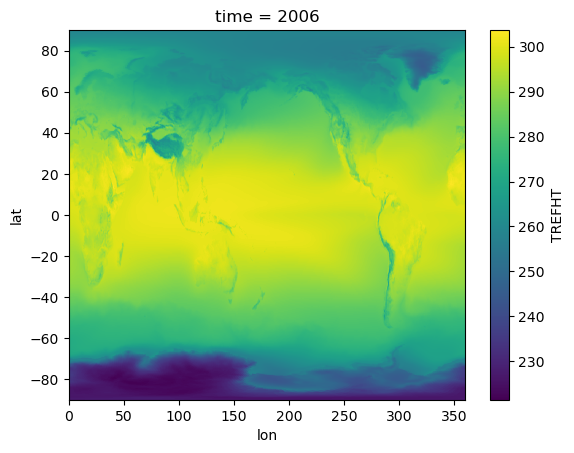

In [48]:
ds_ann_mean2.TREFHT.isel(time=0).plot()

### Just select years 2025 to 2100

In [50]:
ds_ann_mean2.time[19:96]

<xarray.DataArray 'time' (time: 76)>
array([2025, 2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036,
       2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044, 2045, 2046, 2047, 2048,
       2049, 2050, 2051, 2052, 2053, 2054, 2055, 2056, 2057, 2058, 2059, 2060,
       2061, 2062, 2063, 2064, 2065, 2066, 2067, 2068, 2069, 2070, 2071, 2072,
       2073, 2074, 2075, 2076, 2077, 2078, 2079, 2080, 2081, 2082, 2083, 2084,
       2085, 2086, 2087, 2088, 2089, 2090, 2091, 2092, 2093, 2094, 2095, 2096,
       2097, 2098, 2099, 2100])
Coordinates:
  * time     (time) int64 2025 2026 2027 2028 2029 ... 2096 2097 2098 2099 2100

In [74]:
da = ds_ann_mean2.TREFHT.isel(time=slice(19,96)) #- 273.15 #convert to degrees C

In [75]:
for ts in np.arange(0,76,1):
    print(ts, np.max(da))

0 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
1 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
2 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
3 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
4 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
5 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
6 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
7 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
8 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
9 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
10 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
11 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
12 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
13 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
14 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
15 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
16 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
17 <xarray.DataArray 'TREFHT' ()>
array(1.66153499e+35)
18

In [76]:
da = da.where(da<1000)

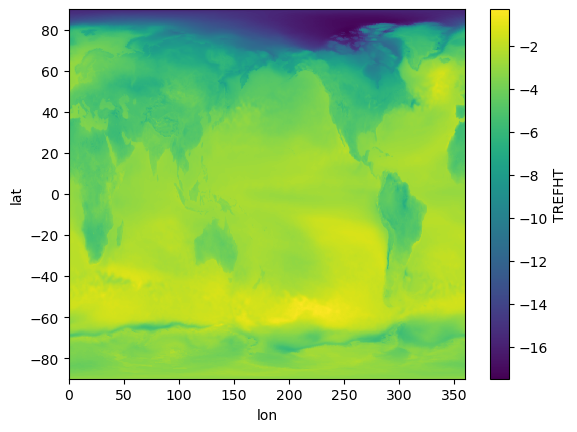

In [77]:
(da.isel(time=0) - da.isel(time=75)).plot()

In [78]:
coeffs = da.polyfit('time', deg=1)

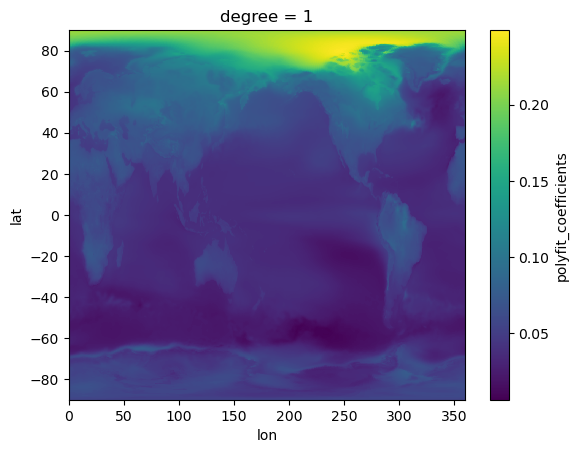

In [79]:
coeffs.polyfit_coefficients.isel(degree=0).plot()

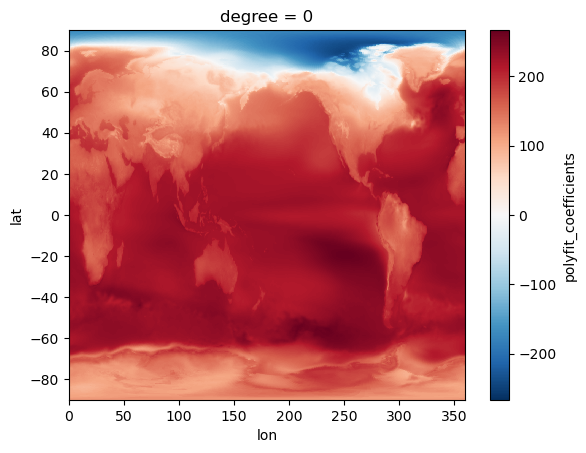

In [80]:
coeffs.polyfit_coefficients.isel(degree=1).plot()

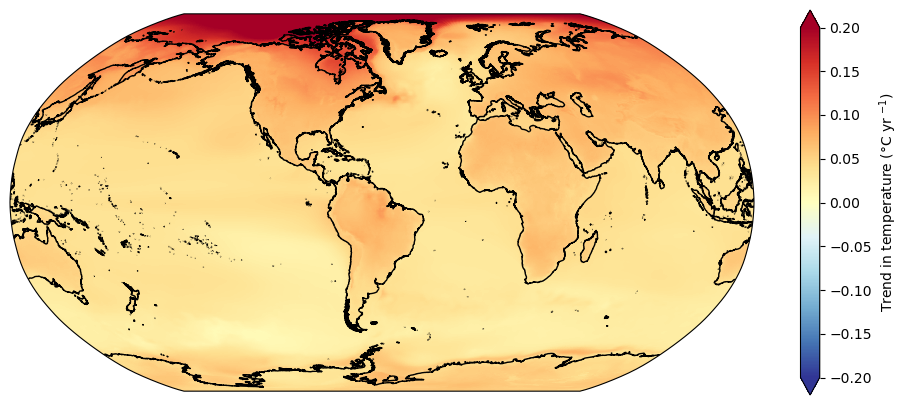

In [83]:
###### 
fig = plt.figure(figsize=(12,5))

ax = fig.add_subplot(1,1,1, projection=ccrs.Robinson(central_longitude=305.0))

#ax.set_title('coccoC at 100m', fontsize=12)
ax.coastlines('10m',linewidth=1)

pc=ax.pcolormesh(ds_ann_mean2.lon, ds_ann_mean2.lat, coeffs.polyfit_coefficients.isel(degree=0), cmap='RdYlBu_r',vmin=-0.2,vmax=0.2,transform=ccrs.PlateCarree())

cbar1 = fig.colorbar(pc, ax=ax,extend='both',label='Trend in temperature (°C yr $^{-1}$)')

fig.savefig('/glade/work/kristenk/figs/2m_temp_trends_MESACLIP_mems1-5_2025to2100.png', bbox_inches='tight', dpi=300, format='png');